# Lab 4

Autoencoders and their types  
By Alex Horyshevskyi  

### Installing dependencies

In [1]:
%pip install keras numpy scikit-image matplotlib albumentations --quiet
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

Using Keras version: 3.13.2
Using PyTorch version: 2.10.0+cu130
Computation will be performed on: cuda


### Load libraries

In [3]:
from keras.layers import Dense, Input, Conv2D, MaxPool2D, UpSampling2D
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from keras.models import Model
from albumentations import Compose, SaltAndPepper
import pandas as pd
import numpy as np

In [4]:
from skimage.metrics import structural_similarity


def plot_images(images, title, indices=None, n=5, seed=81, figsize=(16, 8)):
    """Plot n images; returns chosen indices for reuse."""
    f, ax = plt.subplots(1, n)
    f.set_size_inches(*figsize)
    if indices is None:
        generator = np.random.default_rng(seed=seed)
        indices = generator.choice(len(images), n, replace=False)
    for i, idx in enumerate(indices):
        ax[i].imshow(images[idx].reshape(28, 28), cmap="gray")
        ax[i].axis("off")
    f.suptitle(title)
    plt.tight_layout()
    plt.show()
    return indices


def plot_loss_curves(history, title="Training Loss"):
    """Plot train/val MSE curves from a Keras History object."""
    plt.figure(figsize=(10, 4))
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def make_early_stopping(patience=10, verbose=0):
    """EarlyStopping that restores best weights."""
    return EarlyStopping(
        monitor="val_loss", patience=patience, verbose=verbose,
        mode="auto", min_delta=0, restore_best_weights=True,
    )

## Image reconstruction with autoencoders

### Preparing data

In [5]:
train = pd.read_csv("./fashion-mnist_train.csv")
train_x = train[list(train.columns)[1:]].values
train_y = train['label'].values

## normalize and reshape the predictors
train_x = train_x / 255.0

## create train and validation datasets
train_x, val_x, train_y, val_y = train_test_split(train_x, train_y, test_size=0.2, random_state=81)

## reshape the inputs
train_x = train_x.reshape(-1, 784)
val_x = val_x.reshape(-1, 784)

### Autoencoder architecture

In [6]:
def guide_model() -> Model:
    ## input layer
    input_layer = Input(shape=(784,))
    ## encoding architecture
    encode_layer1 = Dense(1500, activation="relu")(input_layer)
    encode_layer2 = Dense(1000, activation="relu")(encode_layer1)
    encode_layer3 = Dense(500, activation="relu")(encode_layer2)
    ## latent view
    latent_view = Dense(10, activation="sigmoid")(encode_layer3)
    ## decoding architecture
    decode_layer1 = Dense(500, activation="relu")(latent_view)
    decode_layer2 = Dense(1000, activation="relu")(decode_layer1)
    decode_layer3 = Dense(1500, activation="relu")(decode_layer2)
    ## output layer
    output_layer = Dense(784)(decode_layer3)
    model = Model(input_layer, output_layer)
    model.compile(optimizer="adam", loss="mse")
    return model

### Training the autoencoder

In [8]:
guide_autoencoder = guide_model()
guide_autoencoder.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    verbose=1,
    mode="auto",
    min_delta=0,
    restore_best_weights=True,
)
history = guide_autoencoder.fit(
    train_x,
    train_x,
    epochs=50,
    batch_size=256,
    validation_data=(val_x, val_x),
    callbacks=[early_stopping],
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     1,177,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │     1,501,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 500)            │       500,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 500)            │         5,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1000)           │       501,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1500)           │     1,501,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 784)            │     1,176,784 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,368,794 (24.30 MB)

 Trainable params: 6,368,794 (24.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0484 - val_loss: 0.0297
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0250 - val_loss: 0.0225
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0210 - val_loss: 0.0196
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0188 - val_loss: 0.0182
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0175 - val_loss: 0.0174
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0166 - val_loss: 0.0163
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0156 - val_loss: 0.0158
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0151 - val_loss: 0.0149
Epoch 9/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0146 - val_loss: 0.0145
Epoch 10/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0143 - val_loss: 0.0142
Epoch 11/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0139 - val_loss: 0.0141
Epoch 12/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 

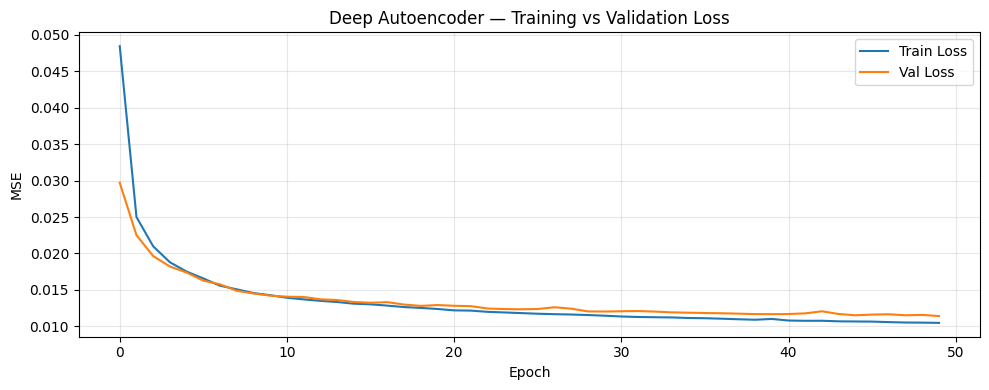

In [9]:
plot_loss_curves(history, "Deep Autoencoder — Training vs Validation Loss")

### Prediction and visualization

 11/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step 

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


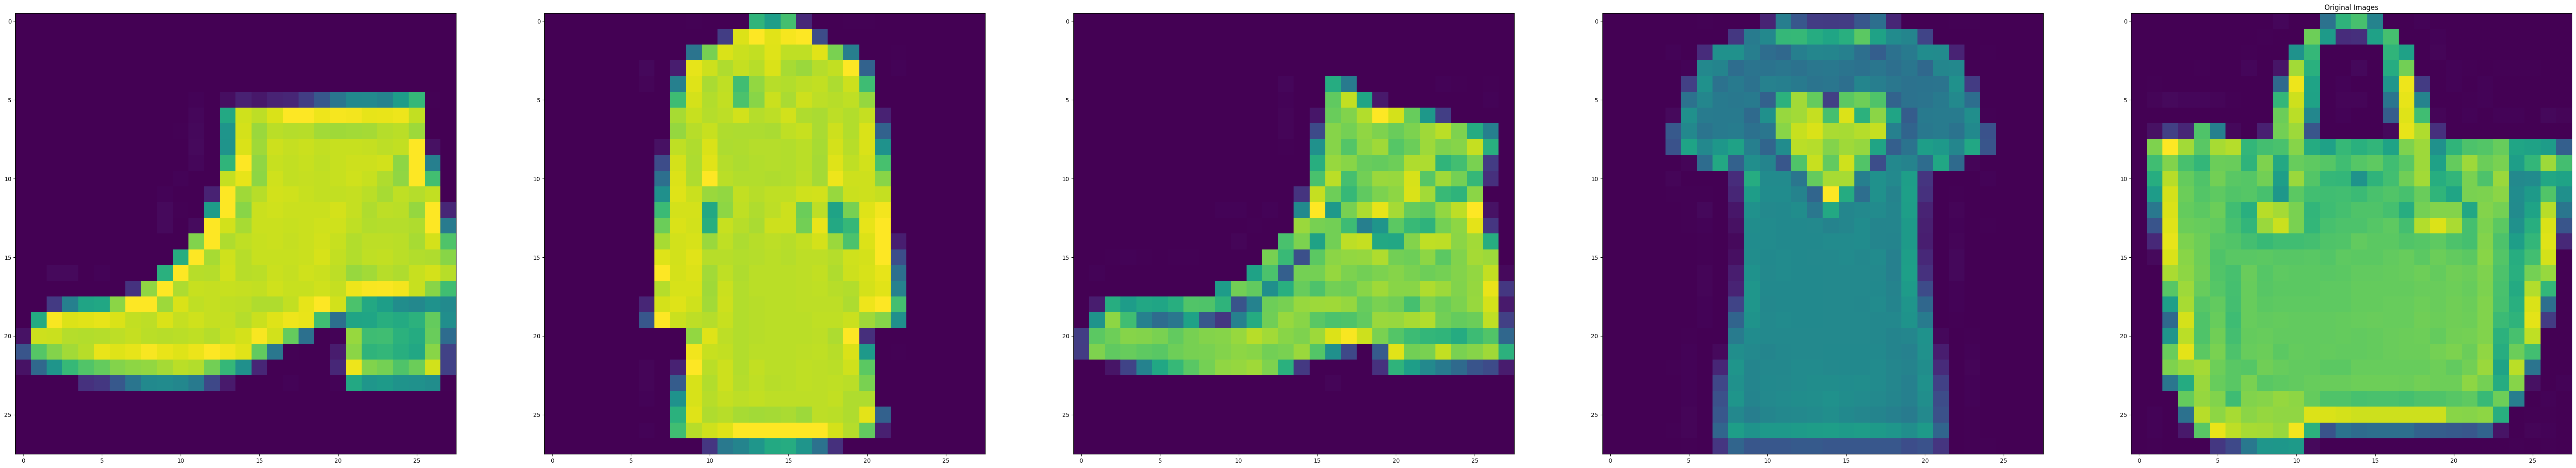

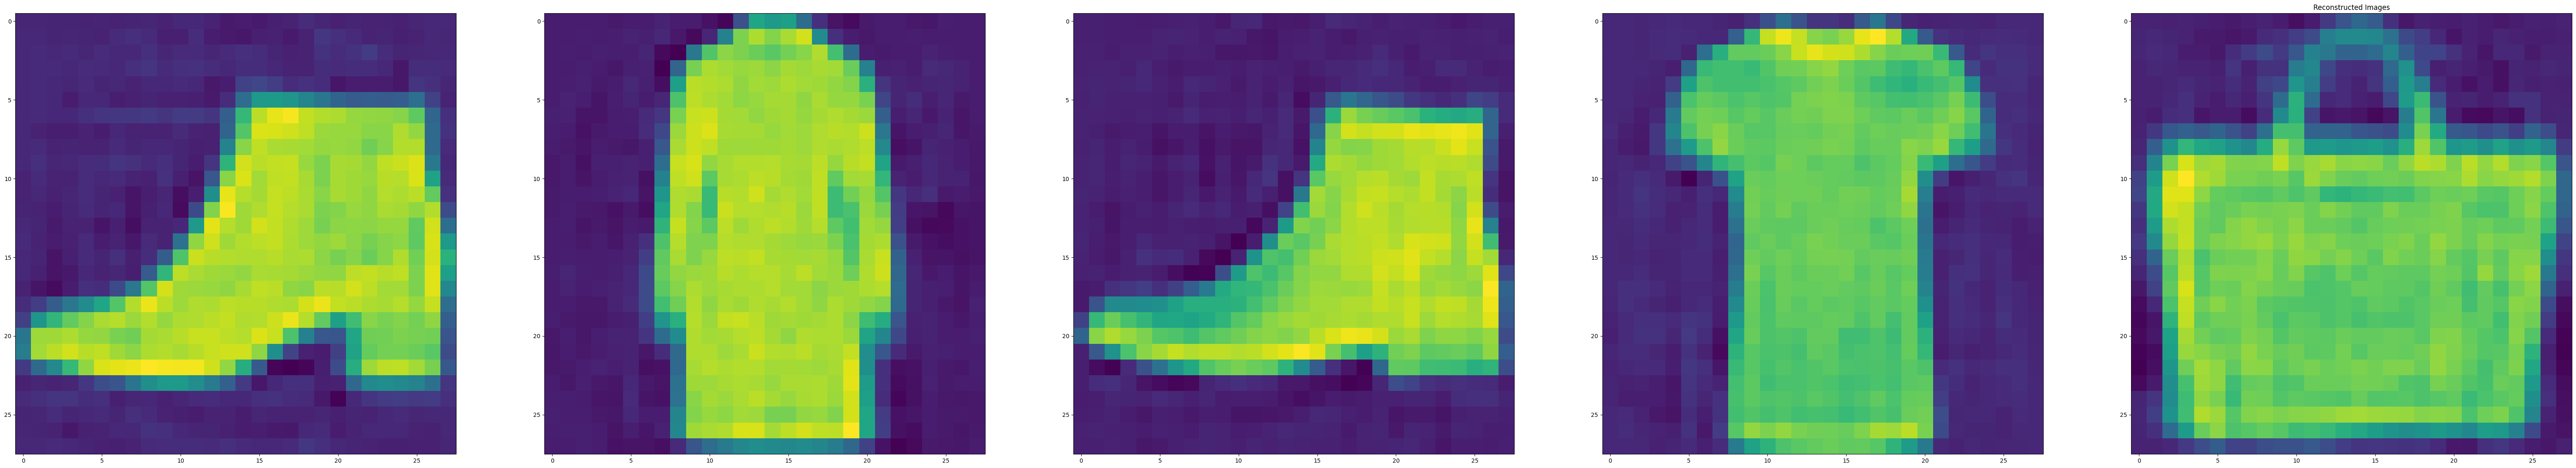

In [10]:
preds_guide = guide_autoencoder.predict(val_x)
del guide_autoencoder
torch.cuda.empty_cache()

f, ax = plt.subplots(1,5)
f.set_size_inches(80, 40)

generator = np.random.default_rng(seed=81)
indices = generator.choice(range(preds_guide.shape[0]), 5, replace=False)
for i, idx in enumerate(indices):
    ax[i].imshow(val_x[idx].reshape(28, 28))
plt.title("Original Images")
plt.show()

f, ax = plt.subplots(1,5)
f.set_size_inches(80, 40)
for i, idx in enumerate(indices):
    ax[i].imshow(preds_guide[idx].reshape(28, 28))
plt.title("Reconstructed Images")
plt.show()

### Task 2: Deep Autoencoder — Parameter Experiments

Varying the bottleneck size (`latent_dim`) while keeping the encoder/decoder architecture fixed
(1500 -> 1000 -> 500 -> **latent** -> 500 -> 1000 -> 1500).

| Experiment | `latent_dim` | Expected behaviour |
|---|---|---|
| Baseline | 10 | already trained above |
| 1 | 5 | higher compression -> lower quality |
| 2 | 32 | moderate relaxation -> improved quality |
| 3 | 64 | low compression -> near-input fidelity |

In [7]:
def build_deep_ae(latent_dim=10):
    """Dense autoencoder with variable bottleneck size (1500->1000->500->latent)."""
    inp = Input(shape=(784,))
    x = Dense(1500, activation="relu")(inp)
    x = Dense(1000, activation="relu")(x)
    x = Dense(500,  activation="relu")(x)
    lat = Dense(latent_dim, activation="sigmoid")(x)
    x = Dense(500,  activation="relu")(lat)
    x = Dense(1000, activation="relu")(x)
    x = Dense(1500, activation="relu")(x)
    out = Dense(784)(x)
    m = Model(inp, out)
    m.compile(optimizer="adam", loss="mse")
    return m

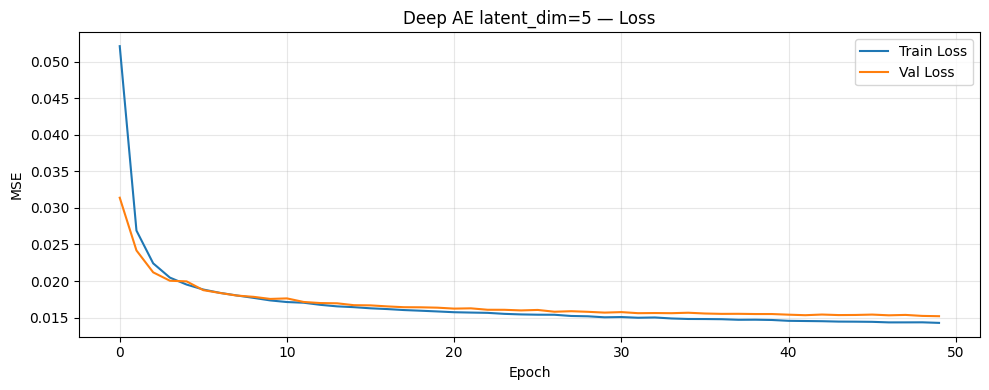

Val MSE (latent=5):  0.01519


In [12]:
# Save baseline val_loss before variable is overwritten by experiment histories
hist_10 = history

# Experiment 1 — latent_dim=5 (higher compression)
ae_5 = build_deep_ae(latent_dim=5)
hist_5 = ae_5.fit(
    train_x, train_x, epochs=50, batch_size=256,
    validation_data=(val_x, val_x),
    callbacks=[make_early_stopping()], verbose=0,
)
preds_5 = ae_5.predict(val_x, verbose=0)
del ae_5; torch.cuda.empty_cache()

plot_loss_curves(hist_5, "Deep AE latent_dim=5 — Loss")
print(f"Val MSE (latent=5):  {hist_5.history['val_loss'][-1]:.5f}")

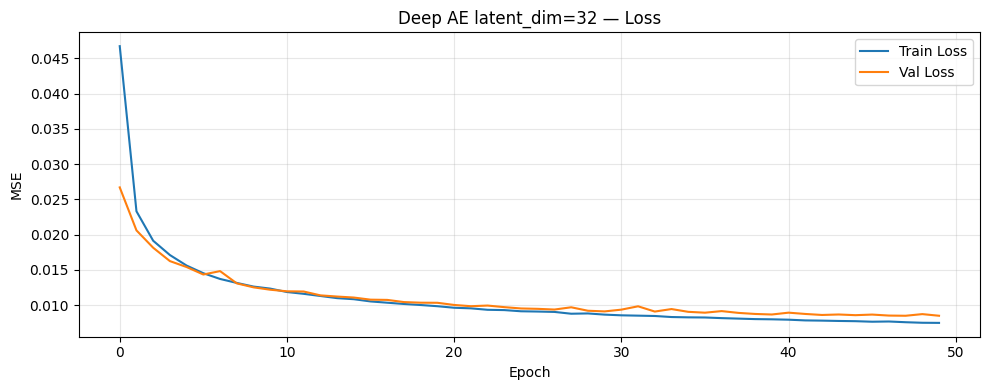

Val MSE (latent=32): 0.00848


In [13]:
# Experiment 2 — latent_dim=32
ae_32 = build_deep_ae(latent_dim=32)
hist_32 = ae_32.fit(
    train_x, train_x, epochs=50, batch_size=256,
    validation_data=(val_x, val_x),
    callbacks=[make_early_stopping()], verbose=0,
)
preds_32 = ae_32.predict(val_x, verbose=0)
del ae_32; torch.cuda.empty_cache()

plot_loss_curves(hist_32, "Deep AE latent_dim=32 — Loss")
print(f"Val MSE (latent=32): {hist_32.history['val_loss'][-1]:.5f}")

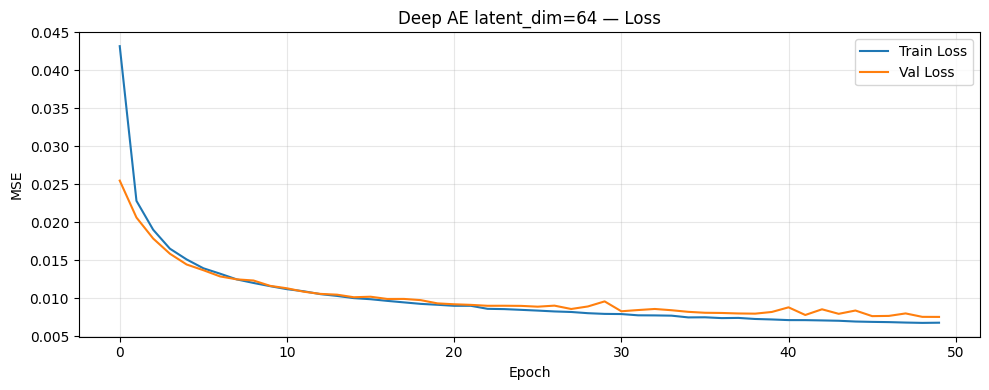

Val MSE (latent=64): 0.00757


In [14]:
# Experiment 3 — latent_dim=64
ae_64 = build_deep_ae(latent_dim=64)
hist_64 = ae_64.fit(
    train_x, train_x, epochs=50, batch_size=256,
    validation_data=(val_x, val_x),
    callbacks=[make_early_stopping()], verbose=0,
)
preds_64 = ae_64.predict(val_x, verbose=0)
del ae_64; torch.cuda.empty_cache()

plot_loss_curves(hist_64, "Deep AE latent_dim=64 — Loss")
print(f"Val MSE (latent=64): {hist_64.history['val_loss'][-1]:.5f}")

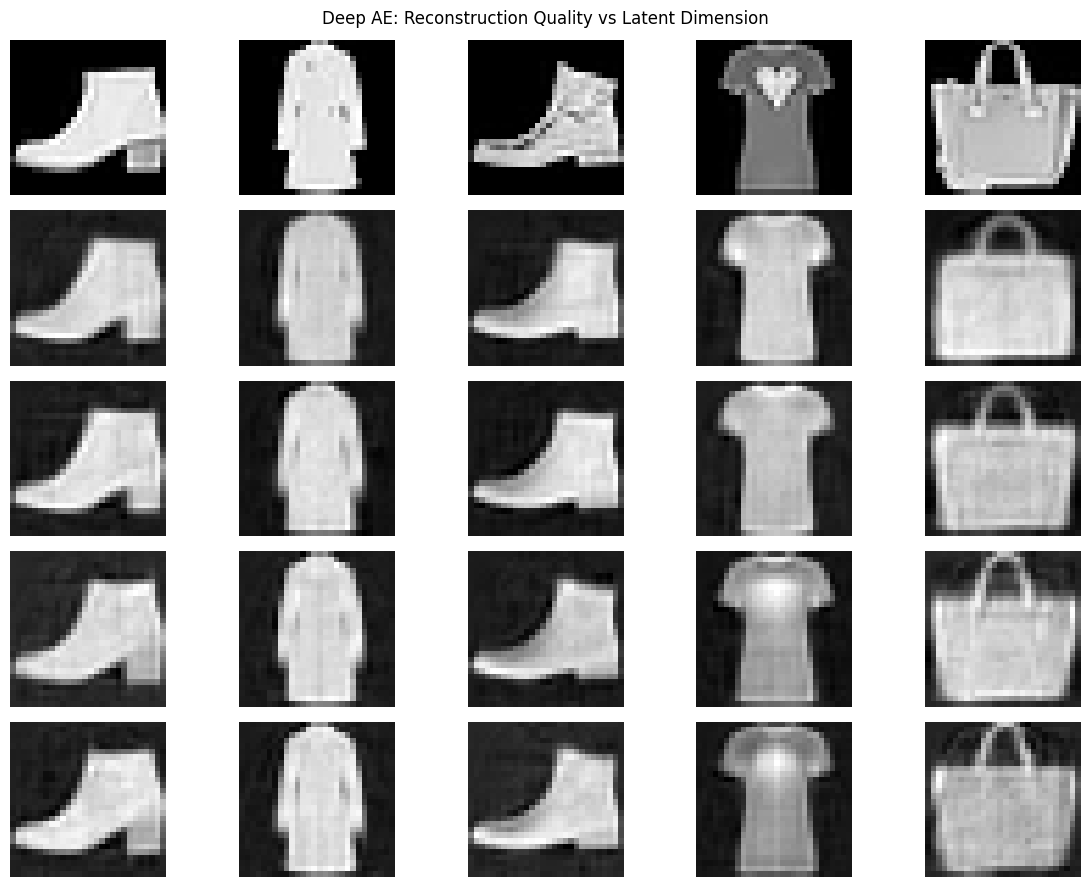

Val MSE summary:
  latent=5 : 0.01519
  latent=10: 0.01141
  latent=32: 0.00848
  latent=64: 0.00757


In [15]:
# Comparison grid: original vs all latent-dim variants
gen = np.random.default_rng(seed=81)
idxs = gen.choice(len(val_x), 5, replace=False)

row_labels  = ["Original", "latent=5", "latent=10 (base)", "latent=32", "latent=64"]
all_recons  = [val_x, preds_5, preds_guide, preds_32, preds_64]

fig, axes = plt.subplots(len(row_labels), 5, figsize=(12, 9))
for r, (label, recon) in enumerate(zip(row_labels, all_recons)):
    for c, idx in enumerate(idxs):
        axes[r, c].imshow(recon[idx].reshape(28, 28), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_ylabel(label, fontsize=9)
fig.suptitle("Deep AE: Reconstruction Quality vs Latent Dimension")
plt.tight_layout()
plt.show()

print("Val MSE summary:")
for name, h in [("latent=5 ", hist_5), ("latent=10", hist_10),
                ("latent=32", hist_32), ("latent=64", hist_64)]:
    print(f"  {name}: {h.history['val_loss'][-1]:.5f}")

## Image denoising with autoencoders

In [10]:
## recreate the train_x array and val_x array
train_x = train[list(train.columns)[1:]].values
train_x, val_x = train_test_split(train_x, test_size=0.2, random_state=391)

## normalize and reshape
train_x = train_x / 255.0
val_x = val_x / 255.0

train_x = train_x.reshape(-1, 28, 28, 1)
val_x = val_x.reshape(-1, 28, 28, 1)

### Noise generation

In [12]:
noise = SaltAndPepper(amount=(0.04, 0.08))
seq_object = Compose([noise])

train_x_n = np.array([seq_object(image=img)["image"] for img in train_x])
val_x_n = np.array([seq_object(image=img)["image"] for img in val_x])

### Data visualization

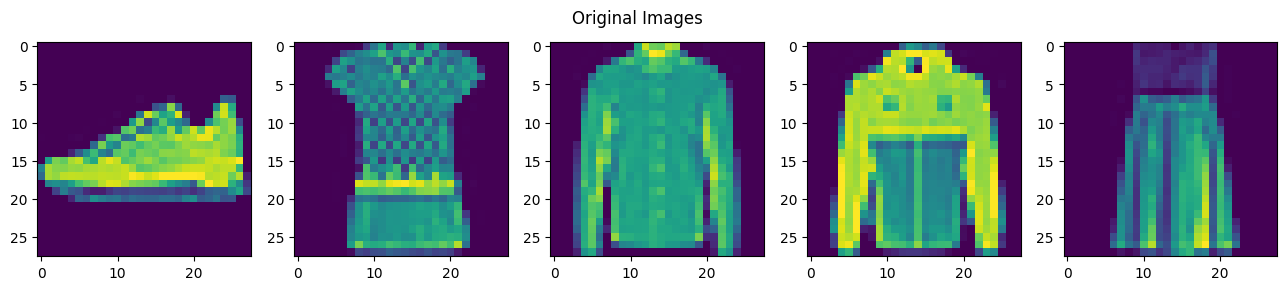

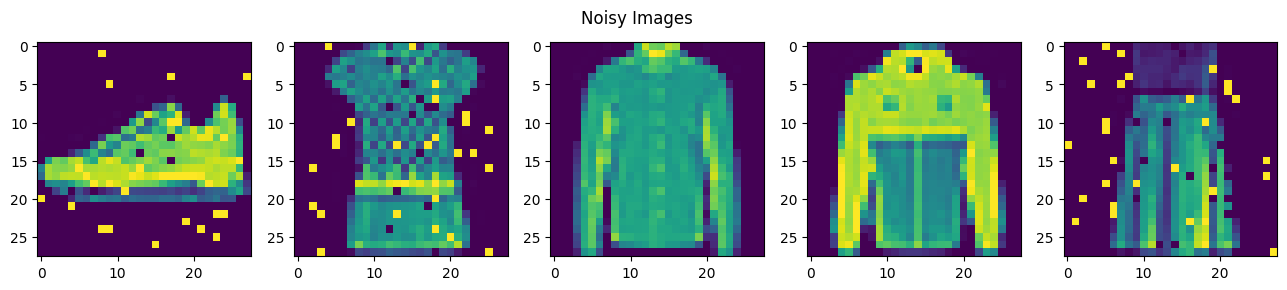

In [18]:
f, ax = plt.subplots(1,5)
f.set_size_inches(16, 8)

generator = np.random.default_rng(seed=42)
indices = generator.choice(range(train_x.shape[0]), 5, replace=False)
for i, idx in enumerate(indices):
    ax[i].imshow(train_x[idx].reshape(28, 28))

f.suptitle("Original Images", y=0.67)
plt.show()

f, ax = plt.subplots(1,5)
f.set_size_inches(16, 8)

generator = np.random.default_rng(seed=42)
indices = generator.choice(range(train_x_n.shape[0]), 5, replace=False)
for i, idx in enumerate(indices):
    ax[i].imshow(train_x_n[idx].reshape(28, 28))

f.suptitle("Noisy Images", y=0.67)
plt.show()

### Denoising with autoencoders

In [8]:
def guide_model_2() -> Model:
    # input layer
    input_layer = Input(shape=(28, 28, 1))
    # encoding architecture
    encoded_layer1 = Conv2D(64, (3, 3), activation='relu', padding='same')(input_layer)
    encoded_layer1 = MaxPool2D( (2, 2), padding='same')(encoded_layer1)
    encoded_layer2 = Conv2D(32, (3, 3), activation='relu', padding='same')(encoded_layer1)
    encoded_layer2 = MaxPool2D( (2, 2), padding='same')(encoded_layer2)
    encoded_layer3 = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded_layer2)
    latent_view = MaxPool2D( (2, 2), padding='same')(encoded_layer3)
    # decoding architecture
    decoded_layer1 = Conv2D(16, (3, 3), activation='relu', padding='same')(latent_view)
    decoded_layer1 = UpSampling2D((2, 2))(decoded_layer1)
    decoded_layer2 = Conv2D(32, (3, 3), activation='relu', padding='same')(decoded_layer1)
    decoded_layer2 = UpSampling2D((2, 2))(decoded_layer2)
    decoded_layer3 = Conv2D(64, (3, 3), activation='relu')(decoded_layer2)
    decoded_layer3 = UpSampling2D((2, 2))(decoded_layer3)
    output_layer = Conv2D(1, (3, 3), padding='same')(decoded_layer3)
    # compile the model
    model = Model(input_layer, output_layer)
    model.compile(optimizer='adam', loss='mse')
    return model

### Training the denoising autoencoder

In [20]:
early_stopping = EarlyStopping(
    monitor="val_loss", min_delta=0, patience=10, verbose=5, mode="auto"
)
guide_autoencoder_2 = guide_model_2()
history = guide_autoencoder_2.fit(
    train_x_n,
    train_x,
    epochs=10,
    batch_size=256,
    validation_data=(val_x_n, val_x),
    callbacks=[early_stopping],
)

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0358 - val_loss: 0.0216
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0192 - val_loss: 0.0179
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0169 - val_loss: 0.0168
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0158 - val_loss: 0.0153
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0149 - val_loss: 0.0148
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0142 - val_loss: 0.0141
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0137 - val_loss: 0.0136
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0131 - val_loss: 0.0130
Epoch 9/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0127 - val_loss: 0.0128
Epoch 10/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0125 - val_loss: 0.0123


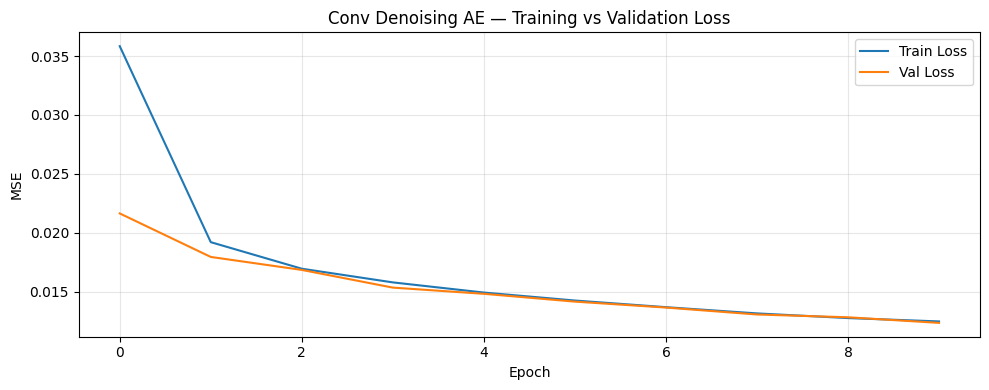

In [21]:
plot_loss_curves(history, "Conv Denoising AE — Training vs Validation Loss")

### Prediction and visualization

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


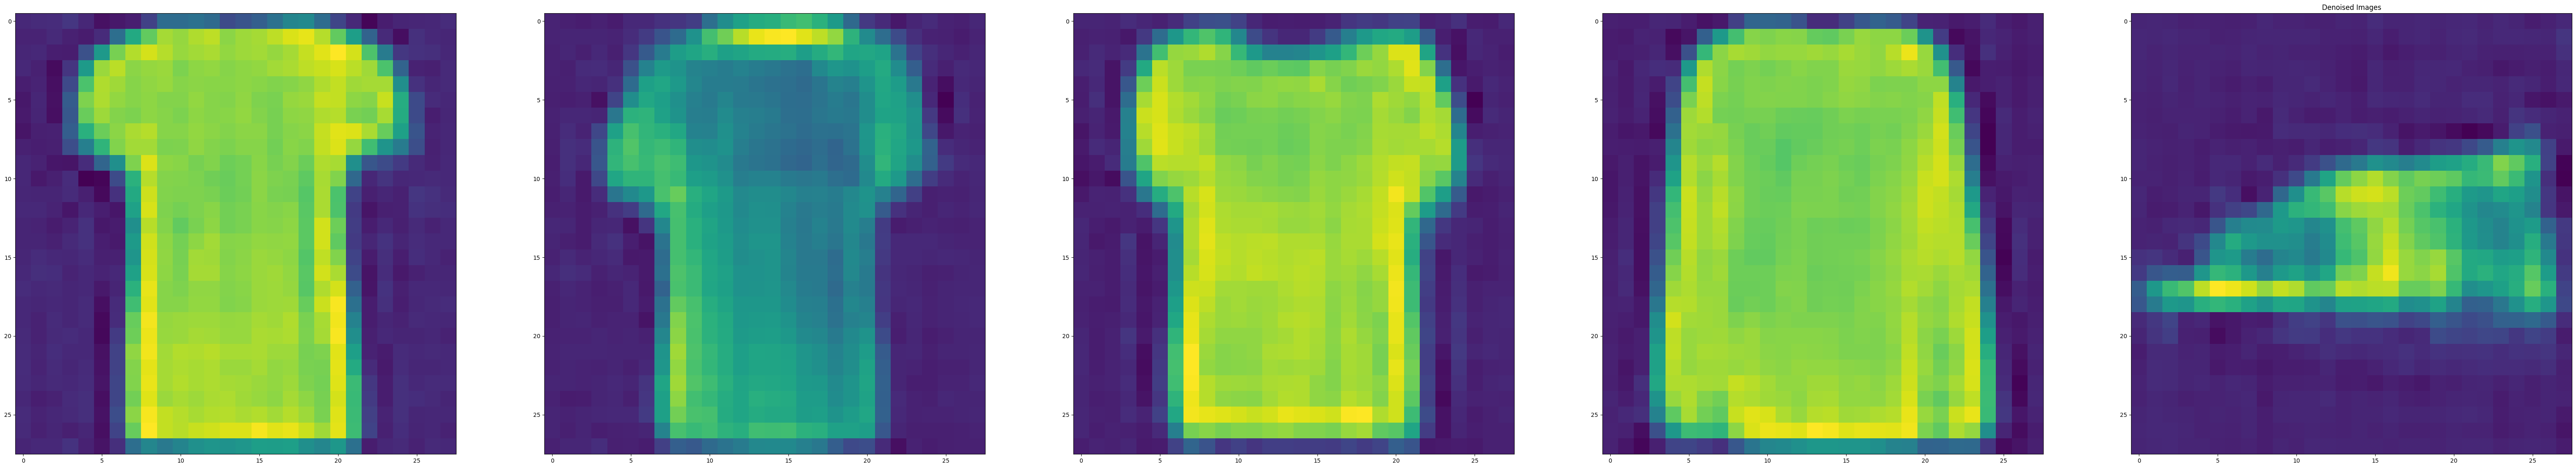

In [22]:
preds_guide_2 = guide_autoencoder_2.predict(val_x_n[:10])
del guide_autoencoder_2
torch.cuda.empty_cache()

f, ax = plt.subplots(1,5)
f.set_size_inches(80, 40)

generator = np.random.default_rng(seed=81)
indices = generator.choice(range(preds_guide_2.shape[0]), 5, replace=False)
for i, idx in enumerate(indices):
    ax[i].imshow(preds_guide_2[idx].reshape(28, 28))

plt.title("Denoised Images")
plt.show()

### Task 3: Convolutional AE — Architecture Modifications

The baseline (`guide_model_2`) uses single Conv2D layers per encoder stage (3 stages, 64->32->16 filters).
Below is a deeper variant with **double conv blocks** per stage, doubling the number of
learned feature maps before each pooling step.

Expected: better reconstruction (lower val_loss) at the cost of more parameters and longer training.

In [23]:
def build_conv_ae_v2() -> Model:
    """Deeper conv AE: double-conv blocks per encoder/decoder stage.

    Spatial dimensions: 28->14->7->4 (encoder), 4->8->16->28 (decoder).
    The no-padding conv in the decoder corrects 16->14 before the final upsample.
    """
    inp = Input(shape=(28, 28, 1))
    # Encoder — double conv per stage
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(inp)
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = MaxPool2D((2, 2), padding="same")(x)            # 14x14
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = MaxPool2D((2, 2), padding="same")(x)            # 7x7
    x = Conv2D(16, (3, 3), activation="relu", padding="same")(x)
    x = Conv2D(16, (3, 3), activation="relu", padding="same")(x)
    latent = MaxPool2D((2, 2), padding="same")(x)       # 4x4
    # Decoder — double conv per stage
    x = Conv2D(16, (3, 3), activation="relu", padding="same")(latent)
    x = Conv2D(16, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)                         # 8x8
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)                         # 16x16
    x = Conv2D(64, (3, 3), activation="relu")(x)        # 14x14 (no padding corrects size)
    x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = UpSampling2D((2, 2))(x)                         # 28x28
    out = Conv2D(1, (3, 3), padding="same")(x)
    m = Model(inp, out)
    m.compile(optimizer="adam", loss="mse")
    return m

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 7, 7, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 4, 4, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 4, 4, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 146,753 (573.25 KB)

 Trainable params: 146,753 (573.25 KB)

 Non-trainable params: 0 (0.00 B)

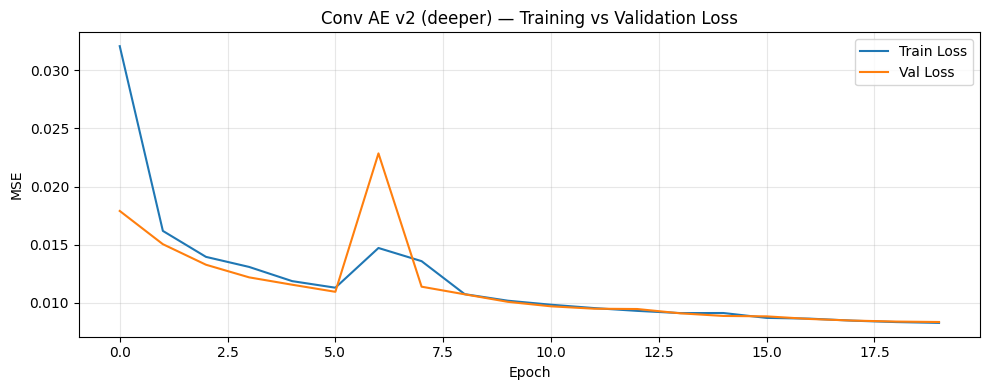

Conv AE v1 val_loss: 0.01233
Conv AE v2 val_loss: 0.00835


In [24]:
ae_v2 = build_conv_ae_v2()
ae_v2.summary()
hist_v2 = ae_v2.fit(
    train_x_n, train_x, epochs=20, batch_size=128,
    validation_data=(val_x_n, val_x),
    callbacks=[make_early_stopping(patience=5)], verbose=0,
)
preds_v2 = ae_v2.predict(val_x_n, verbose=0)
del ae_v2; torch.cuda.empty_cache()

plot_loss_curves(hist_v2, "Conv AE v2 (deeper) — Training vs Validation Loss")
print(f"Conv AE v1 val_loss: {history.history['val_loss'][-1]:.5f}")
print(f"Conv AE v2 val_loss: {hist_v2.history['val_loss'][-1]:.5f}")

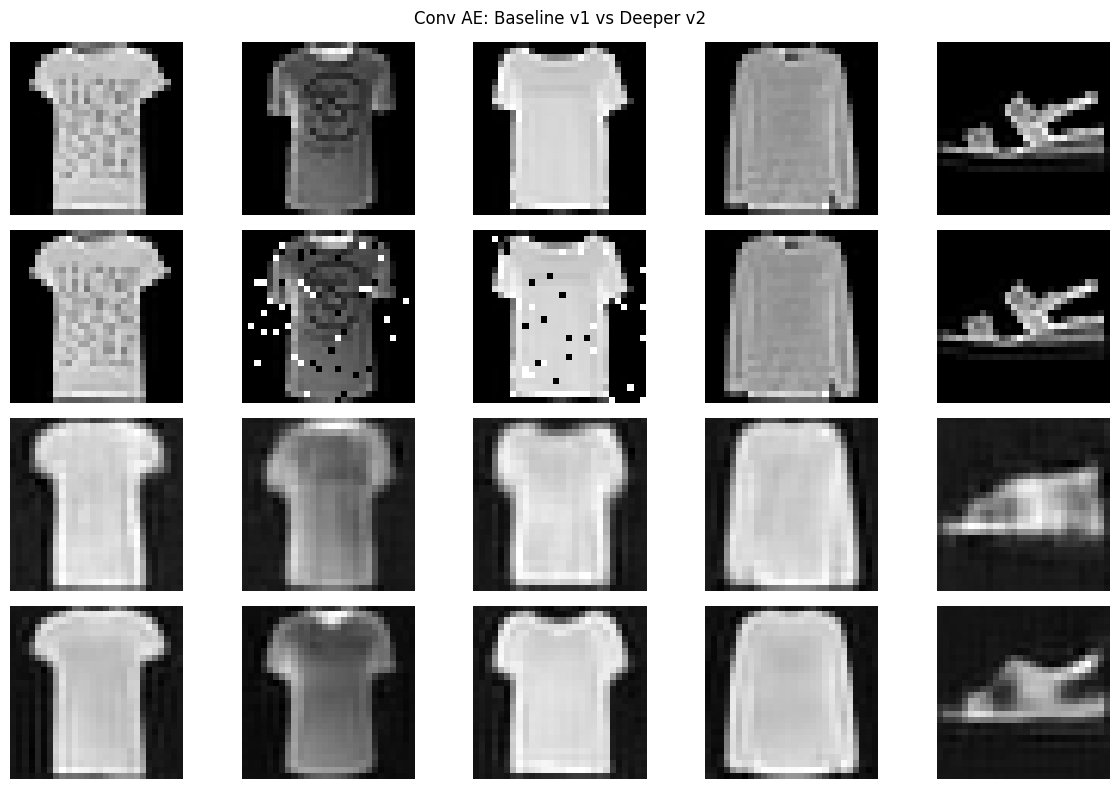

In [25]:
# Side-by-side comparison using first 10 val samples (matches preds_guide_2 shape)
gen = np.random.default_rng(seed=81)
idxs = gen.choice(10, 5, replace=False)

row_labels = ["Clean original", "Noisy (S&P)", "Conv AE v1 denoised", "Conv AE v2 denoised"]
row_data   = [val_x[:10][idxs], val_x_n[:10][idxs],
              preds_guide_2[idxs], preds_v2[:10][idxs]]

fig, axes = plt.subplots(4, 5, figsize=(12, 8))
for r, (label, data) in enumerate(zip(row_labels, row_data)):
    for c in range(5):
        axes[r, c].imshow(data[c].reshape(28, 28), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_ylabel(label, fontsize=8)
fig.suptitle("Conv AE: Baseline v1 vs Deeper v2")
plt.tight_layout()
plt.show()

### Task 4: Local Feature Comparison — Deep AE vs Conv AE

The **deep (dense) AE** treats each 28x28 image as a flat 784-vector. Its encoder has no spatial inductive
bias: all pixels are equally "connected" at each layer, so the bottleneck captures global statistics.

The **convolutional AE** applies weight-shared 3x3 kernels across the spatial grid. Each filter responds
to a local patch, so early layers learn low-level local features (edges, textures) and later layers
compose them. The bottleneck retains a 4x4 spatial map — local structure is preserved, not collapsed.

Below I compare reconstruction quality (MSE + SSIM) and visualise the first conv layer's learned filters.

Model                                 MSE       SSIM
----------------------------------------------------
Deep AE (latent=10, clean->clean)    0.16303     0.1232
Conv AE (noisy->clean, 10 epochs)    0.01007     0.7279


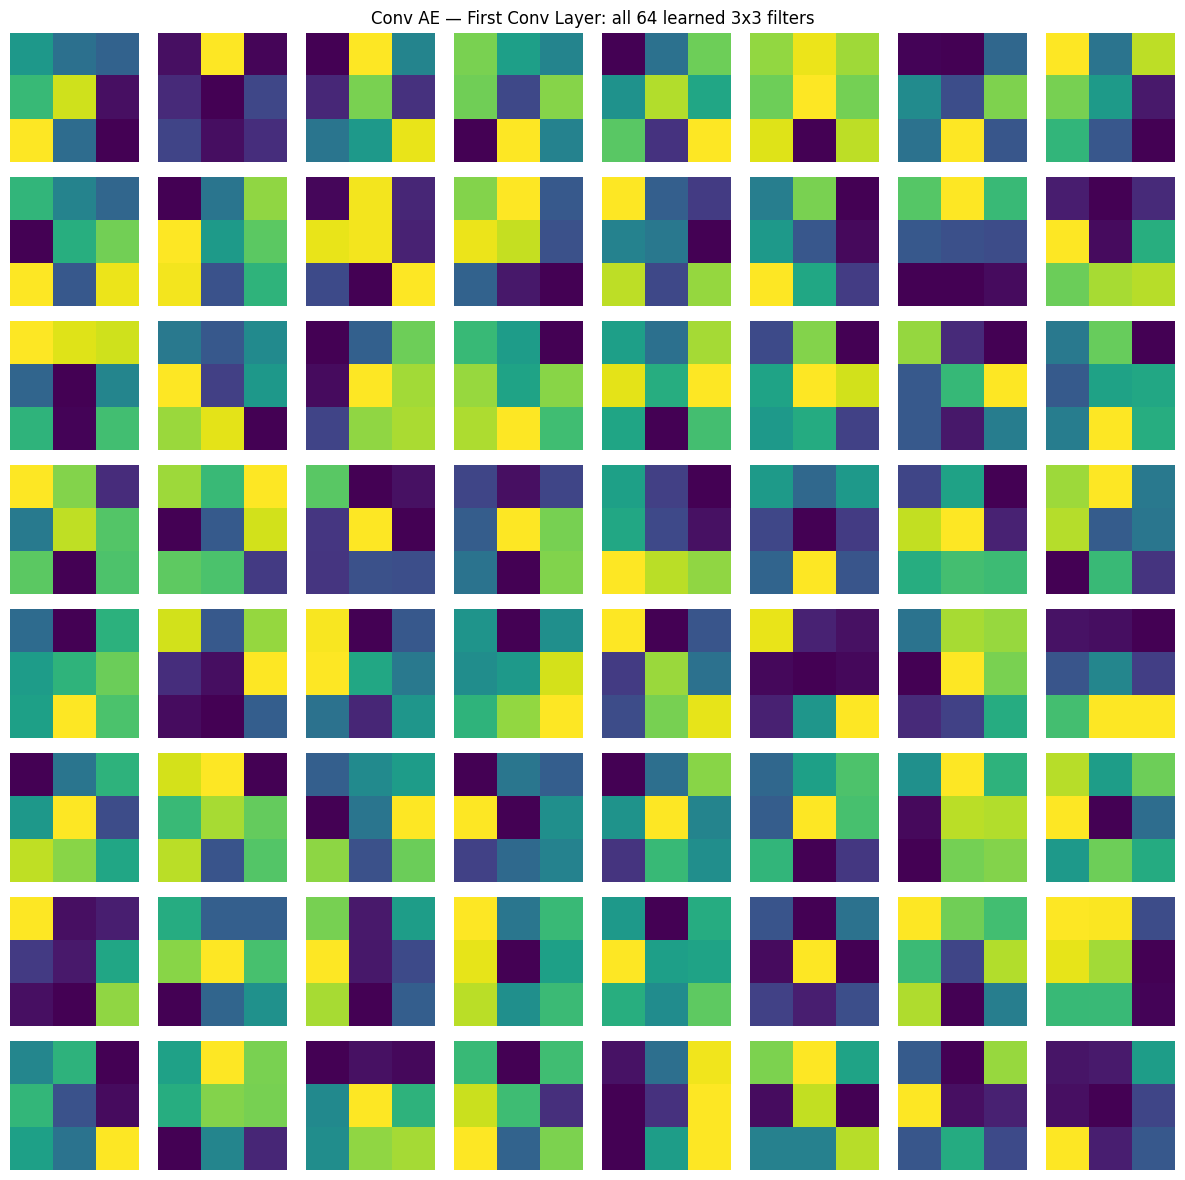

In [26]:
def compute_metrics(originals, reconstructions):
    """Mean MSE and SSIM over a set of image pairs (input shape: Nx784 or Nx28x28x1)."""
    mse_vals, ssim_vals = [], []
    for orig, recon in zip(originals, reconstructions):
        o = orig.reshape(28, 28)
        r = recon.reshape(28, 28)
        mse_vals.append(float(np.mean((o - r) ** 2)))
        ssim_vals.append(float(structural_similarity(o, r, data_range=1.0)))
    return np.mean(mse_vals), np.mean(ssim_vals)


# Retrain a fresh conv AE to get full val-set predictions for fair comparison
ae_cmp = guide_model_2()
ae_cmp.fit(
    train_x_n, train_x, epochs=10, batch_size=128,
    validation_data=(val_x_n, val_x),
    callbacks=[make_early_stopping(patience=5)], verbose=0,
)
preds_conv_full = ae_cmp.predict(val_x, verbose=0)   # clean reconstruction from noisy input

# preds_guide comes from the deep AE section (flat 784 reconstructions on clean input)
deep_mse, deep_ssim = compute_metrics(val_x, preds_guide)
conv_mse, conv_ssim = compute_metrics(val_x, preds_conv_full)

print(f"{'Model':<30} {'MSE':>10} {'SSIM':>10}")
print("-" * 52)
print(f"{'Deep AE (latent=10, clean->clean)':<30} {deep_mse:>10.5f} {deep_ssim:>10.4f}")
print(f"{'Conv AE (noisy->clean, 10 epochs)':<30} {conv_mse:>10.5f} {conv_ssim:>10.4f}")

# Visualise all 64 learned first-layer filters
conv1_weights = ae_cmp.layers[1].get_weights()[0]   # shape (3,3,1,64)
fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    f = conv1_weights[:, :, 0, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)
    ax.imshow(f, cmap="viridis")
    ax.axis("off")
fig.suptitle("Conv AE — First Conv Layer: all 64 learned 3x3 filters")
plt.tight_layout()
plt.show()

del ae_cmp; torch.cuda.empty_cache()

### Task 5: Noise Experiments

Testing the conv denoising AE against different noise types and severities:

| Noise type | Description |
|---|---|
| Gaussian σ=0.15 | Additive normal noise — smoothly distributed corruption |
| Speckle σ=0.2 | Multiplicative noise — corruption scales with pixel intensity |
| S&P 2% | Salt-and-pepper at low severity |
| S&P 8% | Original training noise level |
| S&P 20% | Heavy corruption |

The model is retrained on the original S&P noise (4–8%). Results on out-of-distribution noise types
reveal whether the learned denoiser generalises or overfits to a specific noise profile.

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0236 - val_loss: 0.0163
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0143 - val_loss: 0.0138
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0127 - val_loss: 0.0121
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0117 - val_loss: 0.0118
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0111 - val_loss: 0.0110
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0106 - val_loss: 0.0105
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0102 - val_loss: 0.0102
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0099 - val_loss: 0.0100
Epoch 9/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0097 - val_loss: 0.0096
Epoch 10/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0095 - val_loss: 0.0095
Epoch 11/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 0.0094 - val_loss: 0.0096
Epoch 12/20
750/750 ━━━━━━━━━━

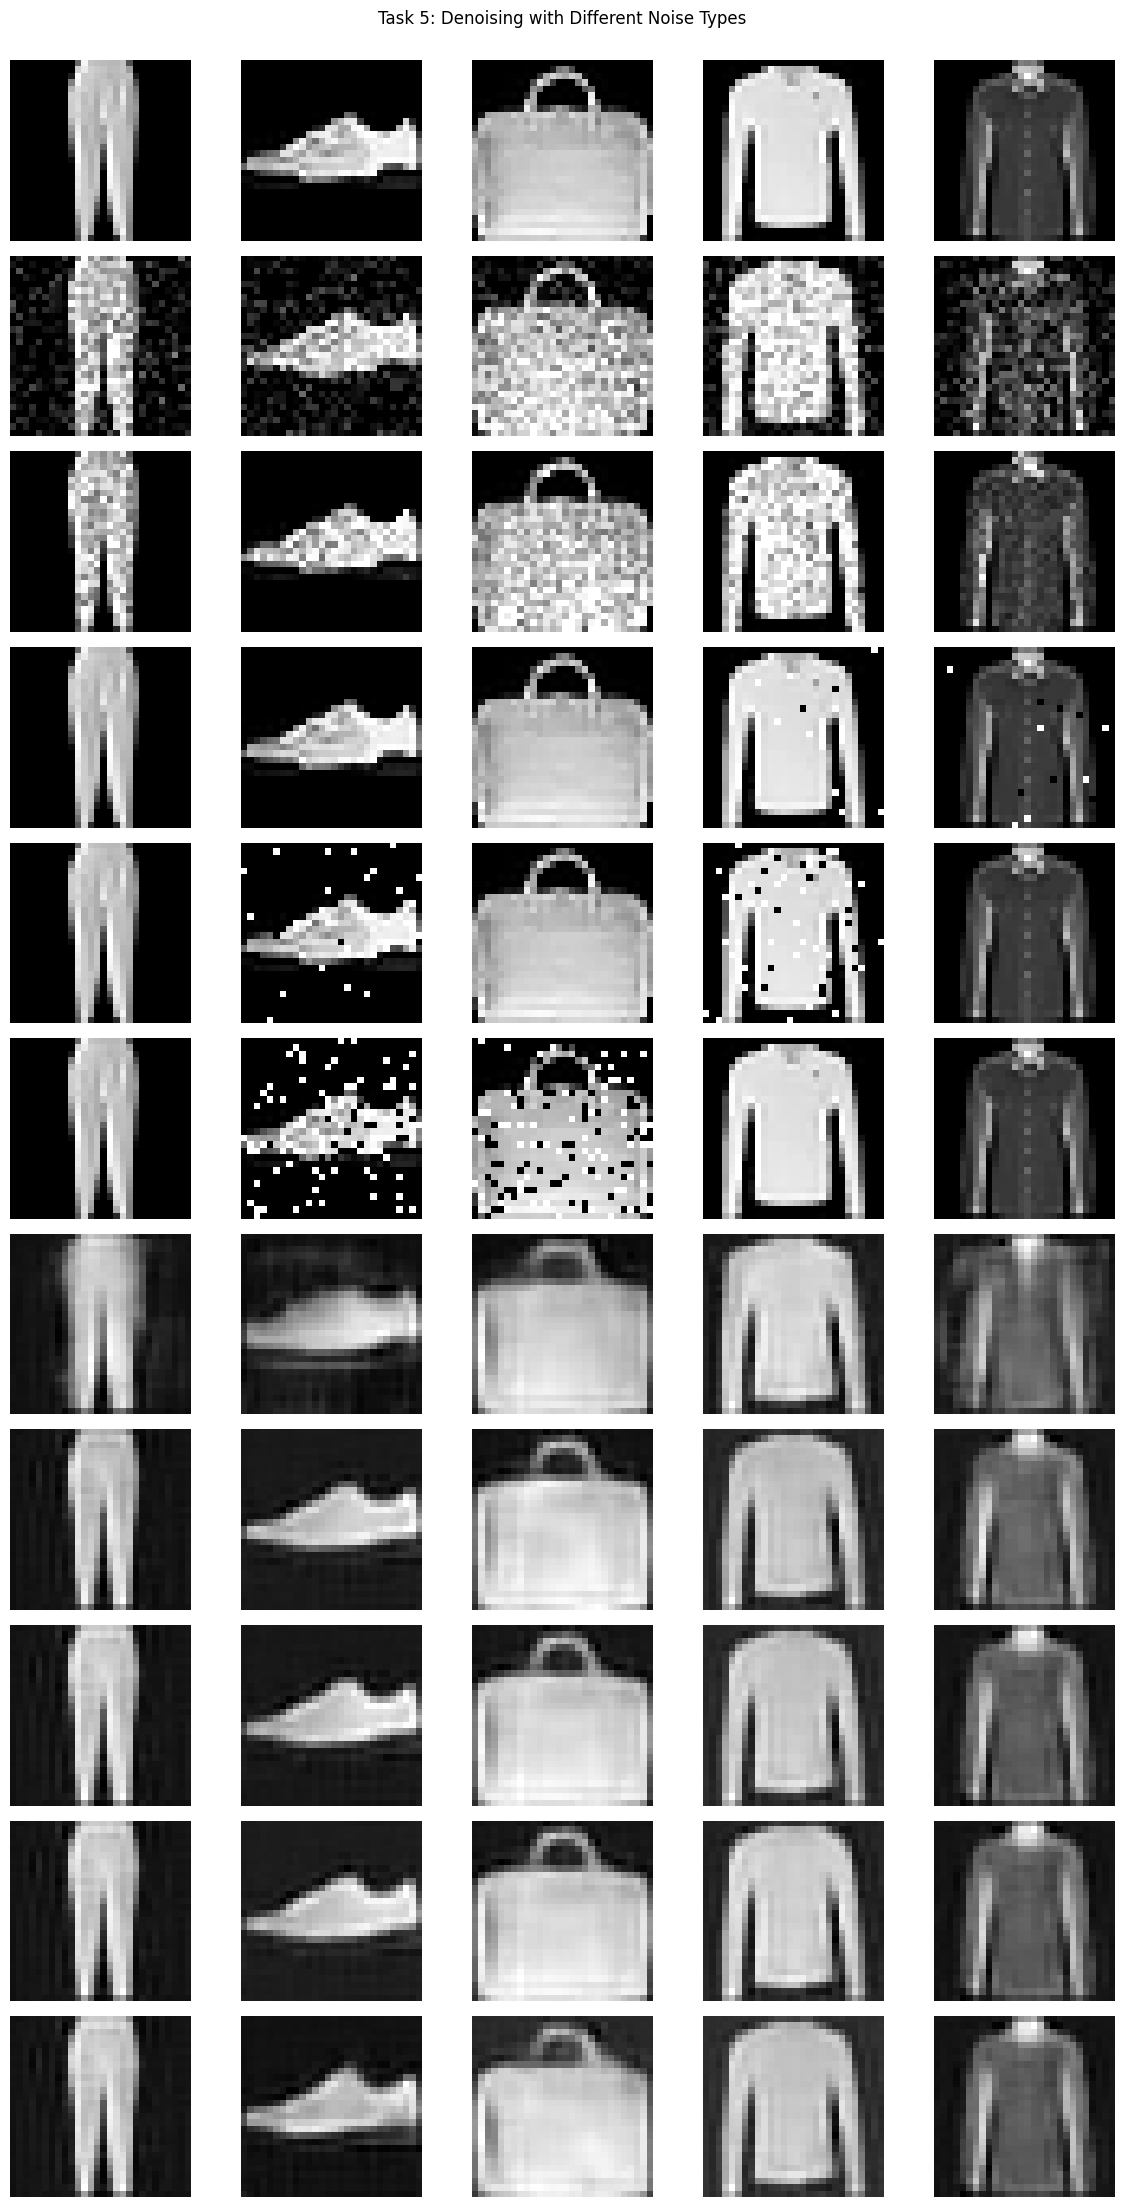

In [ ]:
def apply_gaussian(images, sigma=0.15):
    noisy = images + np.random.default_rng(0).normal(0, sigma, images.shape)
    return noisy.clip(0, 1).astype(np.float32)


def apply_speckle(images, sigma=0.2):
    noisy = images * (1 + np.random.default_rng(1).normal(0, sigma, images.shape))
    return noisy.clip(0, 1).astype(np.float32)


def apply_sp(images, amount):
    seq = Compose([SaltAndPepper(amount=(amount, amount))])
    return np.array([seq(image=img)["image"] for img in images])


noise_configs = [
    ("Gaussian σ=0.15", apply_gaussian(val_x)),
    ("Speckle σ=0.2",   apply_speckle(val_x)),
    ("S&P 2%",          apply_sp(val_x, 0.02)),
    ("S&P 8%",          apply_sp(val_x, 0.08)),
    ("S&P 20%",         apply_sp(val_x, 0.20)),
]

# Retrain denoising AE (guide_autoencoder_2 was deleted in the prediction cell above)
ae_denoise = guide_model_2()
ae_denoise.fit(
    train_x_n, train_x, epochs=20, batch_size=64,
    validation_data=(val_x_n, val_x),
    callbacks=[make_early_stopping(patience=5)], verbose=0,
)

gen = np.random.default_rng(seed=42)
sample_idxs = gen.choice(len(val_x), 5, replace=False)

n_types = len(noise_configs)
fig, axes = plt.subplots(1 + 2 * n_types, 5, figsize=(12, 22))

# Row 0: clean originals
for c, idx in enumerate(sample_idxs):
    axes[0, c].imshow(val_x[idx].reshape(28, 28), cmap="gray")
    axes[0, c].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=8)

for r, (name, noisy_full) in enumerate(noise_configs):
    noisy_sample   = noisy_full[sample_idxs]
    denoised_full  = ae_denoise.predict(noisy_full, verbose=0)
    denoised_sample = denoised_full[sample_idxs]
    noisy_mse = np.mean((val_x - noisy_full) ** 2)
    denoised_mse = np.mean((val_x - denoised_full) ** 2)
    # noisy row
    for c in range(5):
        axes[1 + r, c].imshow(noisy_sample[c].reshape(28, 28), cmap="gray")
        axes[1 + r, c].axis("off")
    axes[1 + r, 0].set_ylabel(f"Noisy\n{name}\nMSE={noisy_mse:.4f}", fontsize=7)
    # denoised row
    for c in range(5):
        axes[1 + n_types + r, c].imshow(denoised_sample[c].reshape(28, 28), cmap="gray")
        axes[1 + n_types + r, c].axis("off")
    axes[1 + n_types + r, 0].set_ylabel(f"Denoised\n{name}\nMSE={denoised_mse:.4f}", fontsize=7)

fig.suptitle("Task 5: Denoising with Different Noise Types", y=1.001)
plt.tight_layout()
plt.show()

del ae_denoise; torch.cuda.empty_cache()